# Hodgkin–Huxley Parameter Estimation

This notebook is a self-contained study of an **inverse problem** in computational neuroscience. From a synthetic noisy recording of membrane voltage, we estimate the sodium, potassium and leak conductances of a Hodgkin–Huxley neuron.

Workflow: (1) define the four coupled ODEs, (2) generate a reference voltage trace, (3) add reproducible Gaussian noise, (4) minimise voltage mean-squared error using differential evolution, and (5) compare the fitted and known conductances. The same protocol and numerical settings appear in the companion Python scripts.

All data are **synthetic**, not experimental measurements. Time is in ms, voltage in mV, current density in µA/cm², conductances in mS/cm² and membrane capacitance in µF/cm².

### Imports
We use `scipy.integrate.solve_ivp` for solving the differential equations and `scipy.optimize.differential_evolution` for the global optimization.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import differential_evolution

## 2. Biological and electrical parameters

The membrane capacitance $C_m$ and reversal potentials $E_{Na}$, $E_K$, $E_L$ are fixed. Only the **maximum conductances** $g_{Na}$, $g_K$ and $g_L$ will be estimated. Their known values generate the test data but are not passed to the fitting objective.

In [2]:
C_m = 1.0     # uF/cm^2
E_Na = 50.0  # mV
E_K = -77.0
E_L = -54.387

TRUE_G_NA = 120.0  # mS/cm^2
TRUE_G_K = 36.0
TRUE_G_L = 0.3
RANDOM_SEED = 42
NOISE_STD_MV = 1.0

## 3. Voltage-dependent gating kinetics

The state is $(V,n,m,h)$: membrane potential, potassium activation, sodium activation and sodium inactivation. Each gating variable $x\in\{n,m,h\}$ satisfies

$$\frac{dx}{dt}=\alpha_x(V)(1-x)-\beta_x(V)x.$$

The classical expressions for $\alpha_n$ and $\alpha_m$ have **removable singularities** at $V=-55$ and $-40$ mV. The helper function below evaluates their limits safely using `expm1`.

In [3]:
def vtrap(x, scale):
    if abs(x) < 1e-8:
        return float(scale)
    return x / (-np.expm1(-x / scale))

def alpha_n(V): return 0.01 * vtrap(V + 55.0, 10.0)
def beta_n(V):  return 0.125 * np.exp(-(V + 65.0) / 80.0)
def alpha_m(V): return 0.1 * vtrap(V + 40.0, 10.0)
def beta_m(V):  return 4.0 * np.exp(-(V + 65.0) / 18.0)
def alpha_h(V): return 0.07 * np.exp(-(V + 65.0) / 20.0)
def beta_h(V):  return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))

## 4. Applied-current protocol

A step current of **10 µA/cm²** is applied from **10 ms to 65 ms**, with zero applied current outside this interval. The voltage trace is simulated from 0 to 80 ms.

In [4]:
def I_inj(t):
    return 10.0 if 10.0 <= t <= 65.0 else 0.0

## 5. Hodgkin–Huxley ODE system

The membrane voltage obeys

$$
C_m\frac{dV}{dt}=I_{\mathrm{inj}}(t)
-g_{Na}m^3h(V-E_{Na})-g_Kn^4(V-E_K)-g_L(V-E_L).
$$

Together with the three gating equations, this gives four coupled nonlinear ODEs. Sodium activation is controlled by $m$, sodium inactivation by $h$ and potassium activation by $n$.

In [5]:
def hodgkin_huxley(t, y, g_Na, g_K, g_L):
    V, n, m, h = y
    dn_dt = alpha_n(V) * (1 - n) - beta_n(V) * n
    dm_dt = alpha_m(V) * (1 - m) - beta_m(V) * m
    dh_dt = alpha_h(V) * (1 - h) - beta_h(V) * h

    I_Na = g_Na * m**3 * h * (V - E_Na)
    I_K = g_K * n**4 * (V - E_K)
    I_L = g_L * (V - E_L)
    dV_dt = (I_inj(t) - I_Na - I_K - I_L) / C_m
    return [dV_dt, dn_dt, dm_dt, dh_dt]

def simulate_hh(conductances, times=None):
    if times is None:
        times = t_eval
    sol = solve_ivp(
        hodgkin_huxley, t_span, y0, args=tuple(conductances),
        t_eval=times, method='BDF', rtol=1e-6, atol=1e-8, max_step=0.5,
    )
    if not sol.success or len(sol.t) != len(times):
        raise RuntimeError(f'HH integration failed: {sol.message}')
    if not np.all(np.isfinite(sol.y)):
        raise RuntimeError('HH integration returned non-finite values')
    return sol

## 6. Simulating the reference neuron

The **BDF** method in SciPy's `solve_ivp` integrates the four coupled equations. The fixed initial state describes a neuron starting near rest. A maximum solver step of 0.5 ms helps resolve the boundaries of the stimulus pulse. We retain the voltage trace and three unobserved gating trajectories.

In [6]:
t_span = (0.0, 80.0)
t_eval = np.linspace(*t_span, 1600)
y0 = [-65.0, 0.317, 0.05, 0.6]  # V (mV), n, m, h

sol = simulate_hh((TRUE_G_NA, TRUE_G_K, TRUE_G_L))
V_experimental = sol.y[0]   # synthetic *noise-free* reference, not measured data
n_experimental, m_experimental, h_experimental = sol.y[1:]
time_steps = sol.t

### Adding reproducible synthetic measurement noise

To imitate an imperfect voltage measurement, independent Gaussian noise with mean 0 mV and standard deviation **1 mV** is added to the reference signal. The random seed is fixed so the results match the companion scripts.

In [7]:
rng = np.random.default_rng(RANDOM_SEED)
noise = rng.normal(0.0, NOISE_STD_MV, V_experimental.shape)
V_noisy = V_experimental + noise

## 7. Visualising the synthetic observations

The noisy recording is the data available to the optimiser. The clean trace is retained only as a reference to evaluate the fit.

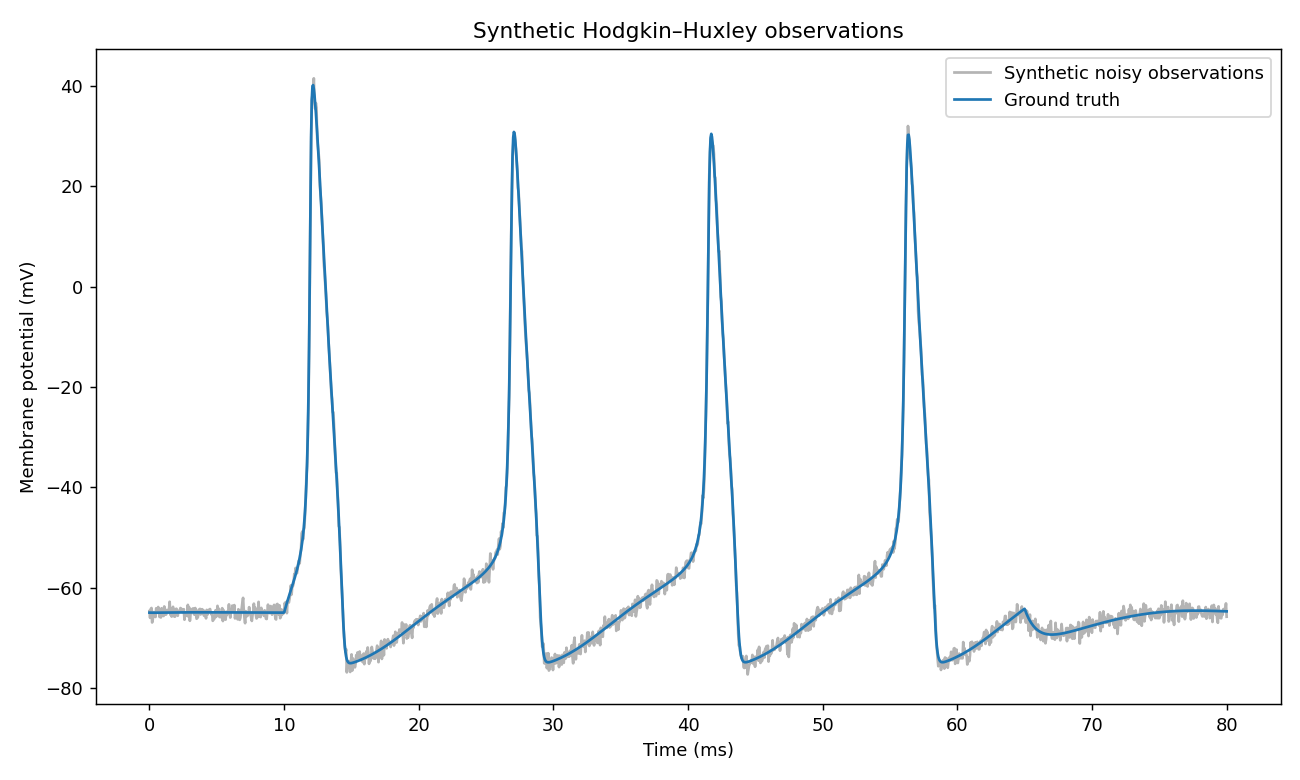

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(time_steps, V_noisy, color='0.35', alpha=0.45, label='Synthetic noisy observations')
plt.plot(time_steps, V_experimental, color='tab:blue', label='Ground truth')
plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title('Synthetic Hodgkin–Huxley observations')
plt.legend()
plt.tight_layout()
plt.show()

### Visualising the internal gating states

Although the inverse problem uses only voltage measurements, the simulator also provides $n(t)$, $m(t)$ and $h(t)$. These curves help inspect the gating dynamics underlying each action potential.

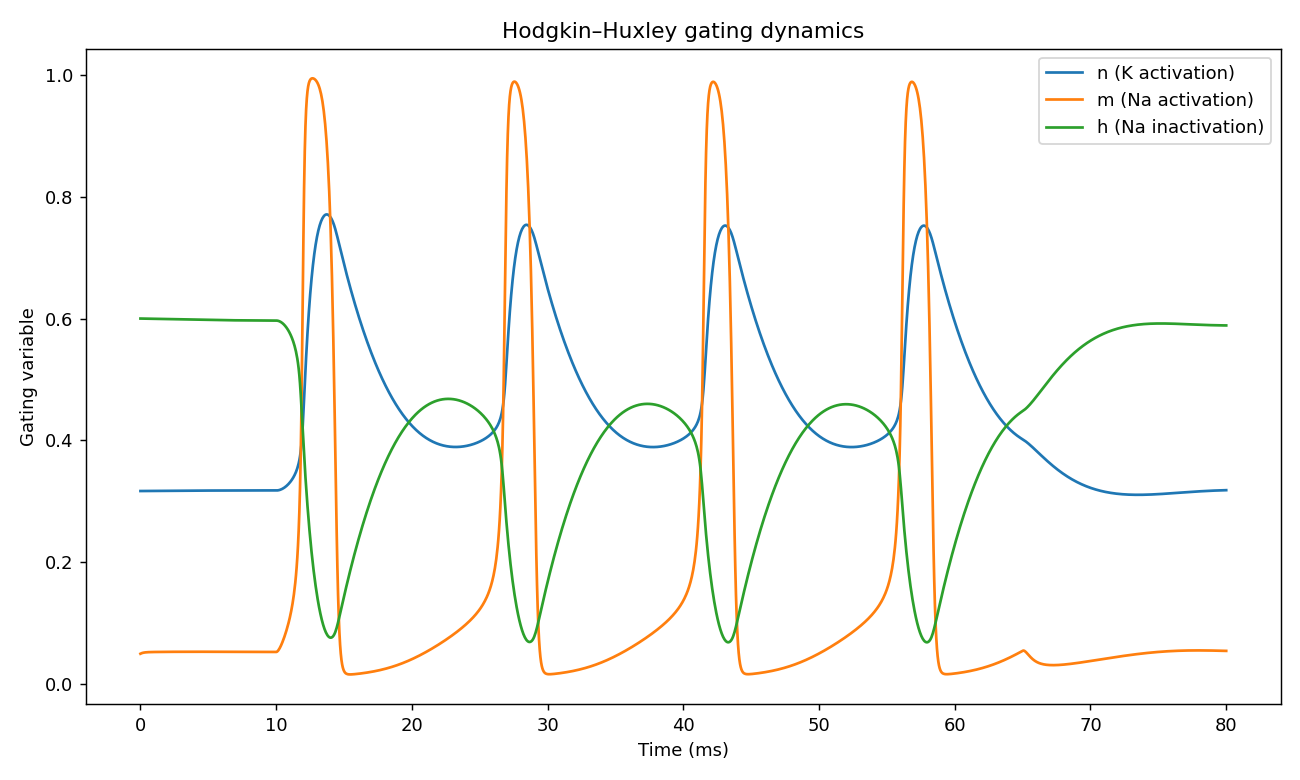

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(time_steps, n_experimental, label='n (K activation)')
plt.plot(time_steps, m_experimental, label='m (Na activation)')
plt.plot(time_steps, h_experimental, label='h (Na inactivation)')
plt.xlabel('Time (ms)')
plt.ylabel('Gating variable')
plt.title('Hodgkin–Huxley gating dynamics')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Estimating the conductances (inverse problem)

The optimiser chooses trial parameters $\theta=(g_{Na},g_K,g_L)$, integrates the model again and compares the predicted voltage $V(t_i;\theta)$ against **the noisy observations** $V_{\mathrm{noisy}}(t_i)$. The loss is the mean squared error:

$$
\mathrm{MSE}(\theta)=\frac{1}{N}\sum_{i=1}^{N}
\left[V(t_i;\theta)-V_{\mathrm{noisy}}(t_i)\right]^2.
$$

Because the observations contain noise, the best-fit parameters need not exactly match the ground truth. Numerical solver failures receive a large penalty.

In [10]:
def objective_function(params):
    try:
        V_predicted = simulate_hh(params, times=t_eval).y[0]
        return float(np.mean((V_noisy - V_predicted)**2))
    except (RuntimeError, ValueError, OverflowError, FloatingPointError):
        return 1e12

## 9. Bounded global optimisation

SciPy's **differential evolution** searches the physically reasonable conductance ranges (in mS/cm²): Na: 50–150, K: 10–50, leak: 0–1. Using a fixed random seed makes the parameter search reproducible; the optimiser's convergence flag should be checked separately from the best parameters it returns.

In [11]:
bounds = [(50.0, 150.0), (10.0, 50.0), (0.0, 1.0)]
print('Starting optimisation...')
result = differential_evolution(
    objective_function, bounds, strategy='best1bin',
    maxiter=30, popsize=10, seed=42, disp=False, polish=True,
)
print('Status:', result.message)
print('Converged:', result.success)
print('Final MSE:', round(result.fun, 6), 'mV^2')
print('Ground truth:', (TRUE_G_NA, TRUE_G_K, TRUE_G_L))
print('Recovered conductances:', result.x)

Starting optimisation...


Status: Maximum number of iterations has been exceeded.
Converged: False
Final MSE: 1.002695 mV^2
Ground truth: (120.0, 36.0, 0.3)
Recovered conductances: [118.40062183  35.72114999   0.29207093]


## 10. Comparing the fitted model with the reference

Simulating the model once more with the fitted conductances provides a direct comparison of the noisy observations, the clean reference and the recovered voltage trace. The mean squared error is measured against the **noisy** data used for fitting.

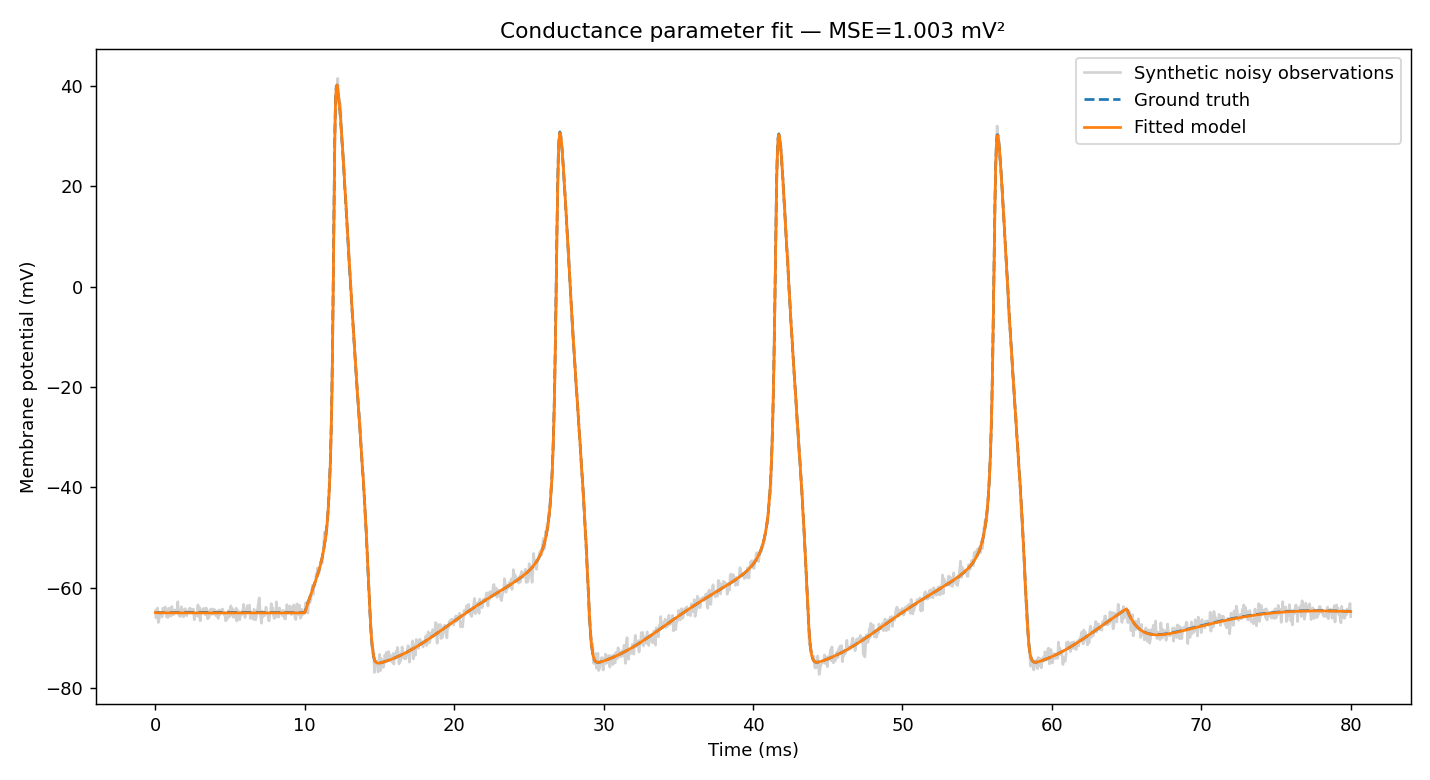

In [12]:
V_fitted = simulate_hh(result.x, times=t_eval).y[0]
mse_fitted = np.mean((V_fitted - V_noisy)**2)

plt.figure(figsize=(11, 6))
plt.plot(time_steps, V_noisy, color='0.5', alpha=0.35, label='Synthetic noisy observations')
plt.plot(time_steps, V_experimental, '--', linewidth=1.5, label='Ground truth')
plt.plot(time_steps, V_fitted, linewidth=1.5, label='Fitted model')
plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title(f'Conductance parameter fit — MSE={mse_fitted:.3f} mV²')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation and limitations

This is a controlled **synthetic-data** demonstration, not parameter estimation from experimental recordings. The stimulus, initial conditions, capacitance and reversal potentials are assumed known, while only the three conductances are fitted. A good voltage fit does not establish that these parameters would be uniquely identifiable under different experimental conditions.